# German power merit order 2026: fuel switching, price formation and gas demand

I build a simple hourly merit order for Germany from the data provided: load, wind and solar, plant availability, and fuel and carbon prices. For every hour it gives a model power price and the fuel that set it, and it tracks how much gas the gas plants burn.

**What I found.** Gas set the model price in about half of all hours (between 42% and 57% in every full month). But as gas got more expensive it dropped behind coal and lignite in the merit order, and gas burn fell by more than half between January and October. So how often gas sets the power price tells you little about how much gas is actually burned. That matters for anyone trading power or gas.

**How to run it.** Put the CSVs in `data/data/` next to this notebook, install `requirements.txt` (Python 3.10) and run all cells. Tables and charts are saved to `outputs/`. I check each step with `assert` statements before building the next one on it, so if something is wrong the notebook stops at that point.

| Step | What it does |
|---|---|
| 1 | Load and check the data |
| 2 | Line up each day's prices with the right delivery day (no prices from the future) |
| 3 | Daily cost (SRMC) of the six plants |
| 4 | Hour-by-hour dispatch |
| 5 | Answers to Q1 to Q4 |
| 6 | What drove the results, and how much my assumptions matter (feeds Q5) |

The brief leaves four choices to me. I set them in the next cell and test them in step 6.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

DATA = Path("data/data")   # where the supplied CSVs are
OUT = Path("outputs")      # everything this notebook produces is saved here
OUT.mkdir(exist_ok=True)

# ---- Numbers given in the brief ------------------------------------------------
MUST_RUN_MW = 8_000        # must-run block at the bottom of the stack (MW)
COAL_MWH_PER_T = 6.98      # energy in one tonne of coal (MWh thermal)
MWH_PER_MCM = 10_550       # 1 mcm of gas = 10.55 GWh = 10,550 MWh thermal

# ---- My assumptions (the brief leaves these open) ------------------------------
# Lignite isn't traded, so it has no market price. 2.9 EUR/MWh thermal is the figure
# DIW Data Documentation 68 uses; Argus uses about 2.85. Sources are in step 3.
LIGNITE_FUEL_EUR_MWH_TH = 2.9
# Price in hours when must-run and renewables cover all demand (residual load <= 8 GW).
MUST_RUN_PRICE = 0.0
# Price when demand is bigger than everything available. None means "use the cost of
# the most expensive plant". That's a floor: a real market would clear higher.
ABOVE_STACK_PRICE = None
# To name one price-setting fuel per day, I take the fuel that was marginal in the most
# hours. If two fuels tie, the one listed first here wins.
TIE_ORDER = ["Above stack", "Gas", "Hard coal", "Lignite", "Must-run / renewables"]

# The six plants, in the same order as stack_plants.csv. Plant 1 is the more efficient
# unit of each fuel and plant 2 the less efficient one.
PLANTS = ["lignite_plant_1", "lignite_plant_2", "hard_coal_plant_1",
          "hard_coal_plant_2", "gas_plant_1", "gas_plant_2"]
# Short names for tables and charts
SHORT = {"lignite_plant_1": "Lignite 1", "lignite_plant_2": "Lignite 2",
         "hard_coal_plant_1": "Coal 1", "hard_coal_plant_2": "Coal 2",
         "gas_plant_1": "Gas 1", "gas_plant_2": "Gas 2"}

# Chart settings. Each fuel keeps the same colour in every chart.
COL = {"Gas": "#2a78d6", "Hard coal": "#eb6834", "Lignite": "#1baf7a",
       "Must-run / renewables": "#eda100", "Above stack": "#e34948"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": "#52514e",
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9, "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200,
    "lines.linewidth": 1.6,
})
pd.set_option("display.width", 160)

## 1. Load and check the data

What the data dictionary says, and what it means for the code:
* The hourly files are stamped with the start of each hour in German local time, with the UTC offset included (`+0100` in winter, `+0200` in summer). I use the offset so the clock-change days come out right.
* Prices are settlements by trade date, on weekdays only. On exchange holidays the previous value may repeat.
* `eurusd` is USD per EUR, so a USD price divided by it gives EUR.
* Lignite has no fuel cost in the file. That's one of my assumptions.

There's also a `max_availability_2019.csv` in the folder. It isn't in the data dictionary, it's for a different year and it includes a nuclear plant, so I don't use it.

In [2]:
# Print the data dictionary so it's on record in the notebook
print((DATA / "data_dictionary.txt").read_text())

InterviewTask - German power stack - data dictionary
Period: 2026-01-01 to 2026-11-12. All times CET (German local time; CEST in summer, UTC offset shown).

load_wind_solar_DE_hourly_2026.csv (hourly, Germany/Luxembourg, actuals)
  timestamp_cet                                          start of hour
  load_mw, wind_onshore_mw, wind_offshore_mw, solar_mw   MW (hourly average)

availability_DE_hourly_2026.csv (hourly available capacity by plant, MW)
  timestamp_cet                                          start of hour
  lignite_plant_1_mw, lignite_plant_2_mw, hard_coal_plant_1_mw, hard_coal_plant_2_mw, gas_plant_1_mw, gas_plant_2_mw

max_availability_2026.csv
  plant, max_available_mw                                highest hourly available capacity of each plant, MW

fuel_prices_daily_2026.csv (settlements by trade date; weekdays only, on exchange holidays the previous value may repeat)
  gas_eur_mwh   gas, EUR/MWh thermal
  eua_eur_t     EU carbon allowance, EUR/t CO2
  coal_usd_t    c

In [3]:
def load_hourly(name):
    """Read one of the hourly files and add two columns: ts (local timestamp) and day.

    Stamps look like "2026-03-29 03:00 +0200". I parse them to UTC first because the
    offset makes every hour unique. On 25 October the clock goes back and 02:00 happens
    twice, once at +0200 and once at +0100. Going through UTC keeps those as two hours.
    """
    df = pd.read_csv(DATA / name)
    utc = pd.to_datetime(df["timestamp_cet"], format="%Y-%m-%d %H:%M %z", utc=True)
    local = utc.dt.tz_convert("Europe/Berlin")
    # Converting back to local time should give exactly the stamp in the file.
    # If it doesn't, I've misread the format.
    assert (local.dt.strftime("%Y-%m-%d %H:%M %z") == df["timestamp_cet"]).all(), name
    df.insert(0, "ts", local)
    # The delivery day is the German calendar date (00:00 to 23:00 local time)
    df.insert(1, "day", local.dt.tz_localize(None).dt.normalize())
    return df.drop(columns="timestamp_cet")

lws = load_hourly("load_wind_solar_DE_hourly_2026.csv")      # load, wind and solar (MW)
avail = load_hourly("availability_DE_hourly_2026.csv")       # available capacity by plant (MW)
plants = pd.read_csv(DATA / "stack_plants.csv").set_index("plant")   # fuel, efficiency, CO2, O&M
max_avail = pd.read_csv(DATA / "max_availability_2026.csv").set_index("plant")["max_available_mw"]
prices_raw = pd.read_csv(DATA / "fuel_prices_daily_2026.csv", parse_dates=["date"])  # daily settlements

# The plant files should list the same six plants, in the same order as PLANTS
assert list(plants.index) == PLANTS and list(max_avail.index) == PLANTS
plants

,fuel,efficiency,co2_t_per_mwh_th,vom_eur_mwh,fuel_cost_eur_mwh_th
plant,,,,,
lignite_plant_1,Lignite,0.43,0.364,3,NaN
lignite_plant_2,Lignite,0.37,0.364,3,NaN
hard_coal_plant_1,Hard coal,0.46,0.341,3,coal_usd_t / eurusd / 6.98
hard_coal_plant_2,Hard coal,0.40,0.341,3,coal_usd_t / eurusd / 6.98
gas_plant_1,Gas,0.60,0.202,2,gas_eur_mwh
gas_plant_2,Gas,0.45,0.202,2,gas_eur_mwh


In [4]:
def check_hourly(df, name):
    """Basic quality checks for one hourly file: gaps, duplicates, missing values,
    negative values, and any day that doesn't have 24 hours."""
    vals = df.drop(columns=["ts", "day"])
    full = pd.date_range(df["ts"].min(), df["ts"].max(), freq="h")   # every hour that should be there
    per_day = df.groupby("day").size()
    return pd.Series({
        "rows": len(df),
        "first hour": df["ts"].min(), "last hour": df["ts"].max(),
        "missing hours": len(full.difference(df["ts"])),
        "duplicate hours": int(df["ts"].duplicated().sum()),
        "missing values": int(vals.isna().sum().sum()),
        "negative values": int((vals < 0).sum().sum()),
        "days not 24h": ", ".join(f"{d:%d %b}={n}h" for d, n in per_day[per_day != 24].items()),
    }, name=name)

report = pd.concat([check_hourly(lws, "load/wind/solar"), check_hourly(avail, "availability")], axis=1)
report

,load/wind/solar,availability
rows,7584,7584
first hour,2026-01-01 00:00:00+01:00,2026-01-01 00:00:00+01:00
last hour,2026-11-12 23:00:00+01:00,2026-11-12 23:00:00+01:00
missing hours,0,0
duplicate hours,0,0
missing values,0,0
negative values,0,0
days not 24h,"29 Mar=23h, 25 Oct=25h","29 Mar=23h, 25 Oct=25h"


In [5]:
# The same checks as asserts, so the notebook stops here if the data isn't what the model expects
for df in (lws, avail):
    assert df["ts"].is_monotonic_increasing and not df["ts"].duplicated().any()   # in order, no repeats
    assert df.drop(columns=["ts", "day"]).notna().all().all()                     # no blanks
    assert (df.drop(columns=["ts", "day"]) >= 0).all().all()                       # nothing negative
assert (lws["ts"] == avail["ts"]).all(), "the two hourly files must cover the same hours"

# Germany changes its clocks on 29 March (a 23-hour day) and 25 October (a 25-hour day).
# Every other day should have 24 hours.
hours_per_day = lws.groupby("day").size()
assert hours_per_day[pd.Timestamp("2026-03-29")] == 23
assert hours_per_day[pd.Timestamp("2026-10-25")] == 25
assert (hours_per_day.drop([pd.Timestamp("2026-03-29"), pd.Timestamp("2026-10-25")]) == 24).all()

# Each plant's hourly availability should never be above its static maximum
cap_check = pd.DataFrame({
    "static max (MW)": max_avail,
    "highest hourly (MW)": [avail[p + "_mw"].max() for p in PLANTS],
    "lowest hourly (MW)": [avail[p + "_mw"].min() for p in PLANTS],
    "hours above max": [(avail[p + "_mw"] > max_avail[p]).sum() for p in PLANTS],
    "hours at zero": [(avail[p + "_mw"] == 0).sum() for p in PLANTS],
})
assert (cap_check["hours above max"] == 0).all()
print("Plant 1 and plant 2 have identical availability within each fuel:",
      all((avail[f + "_plant_1_mw"] == avail[f + "_plant_2_mw"]).all() for f in ["lignite", "hard_coal", "gas"]))
cap_check

Plant 1 and plant 2 have identical availability within each fuel: True


,static max (MW),highest hourly (MW),lowest hourly (MW),hours above max,hours at zero
plant,,,,,
lignite_plant_1,7282,7282,2877,0,0
lignite_plant_2,7282,7282,2877,0,0
hard_coal_plant_1,4896,4896,1936,0,0
hard_coal_plant_2,4896,4896,1936,0,0
gas_plant_1,14834,14834,10266,0,0
gas_plant_2,14834,14834,10266,0,0


In [6]:
# Price checks: one row per weekday, no blanks, and units that make sense
p = prices_raw
assert p["date"].is_monotonic_increasing and not p["date"].duplicated().any()   # dates in order, no repeats
assert p.notna().all().all() and (p.drop(columns="date") > 0).all().all()       # no blanks, all positive
assert (p["date"].dt.dayofweek < 5).all()                                       # weekdays only (Mon=0 to Fri=4)
# USD per EUR is around 1.0 to 1.2. If it were EUR per USD it would be below 1.
assert p["eurusd"].between(0.9, 1.4).all(), "eurusd should be USD per EUR"
# Efficiency should be written as 0.58, not 58
assert plants["efficiency"].between(0.2, 0.7).all(), "efficiency should be a fraction, not a percent"
# Weekdays with no settlement (exchange holidays)
missing_bd = pd.bdate_range(p["date"].min(), p["date"].max()).difference(p["date"])
print(f"Price rows: {len(p)}, {p['date'].min():%d %b %Y} to {p['date'].max():%d %b %Y}")
print("Weekdays with no row:", [f"{d:%d %b %Y}" for d in missing_bd])
print("Days where a value repeats the previous one:",
      {c: int((p[c].diff() == 0).sum()) for c in p.columns[1:]})
p.drop(columns="date").describe().T[["min", "mean", "max"]].round(3)

Price rows: 233, 22 Dec 2025 to 12 Nov 2026
Weekdays with no row: ['01 Jan 2026']
Days where a value repeats the previous one: {'gas_eur_mwh': 9, 'eua_eur_t': 5, 'coal_usd_t': 22, 'eurusd': 2}


,min,mean,max
gas_eur_mwh,26.292,54.325,104.000
eua_eur_t,63.650,80.469,92.240
coal_usd_t,93.700,120.675,153.850
eurusd,1.106,1.156,1.204


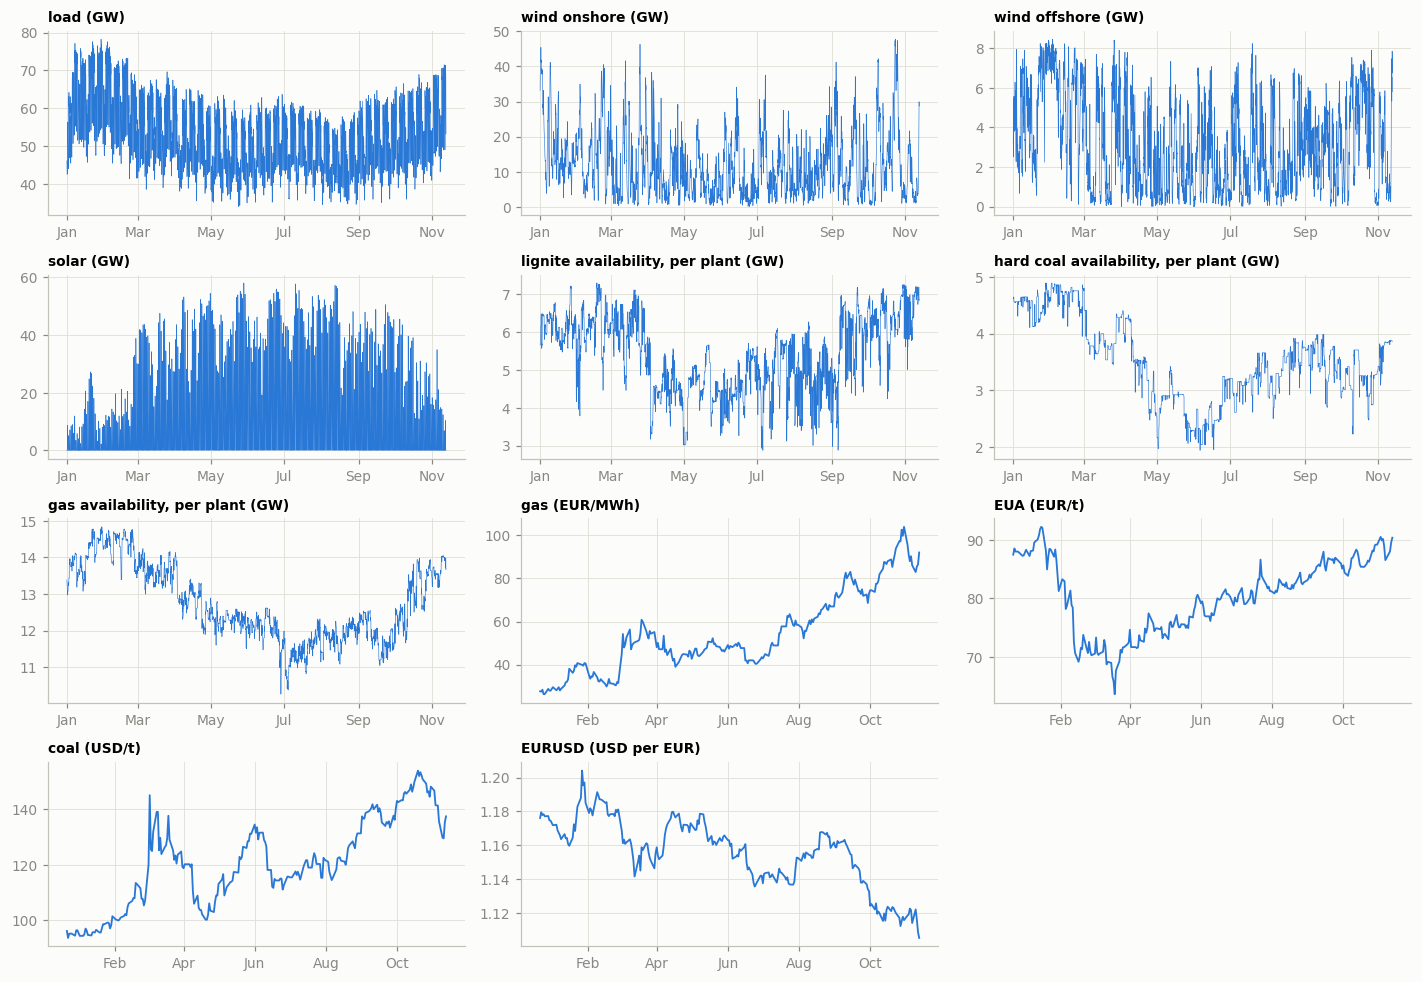

In [7]:
# Plot every series once, just to look for anything strange: spikes, flat lines, gaps
fig, axes = plt.subplots(4, 3, figsize=(13, 9))
axes = axes.ravel()
# (data, column, title, scale) for each hourly series; MW are shown as GW
series = (
    [(lws, c, c.replace("_mw", "").replace("_", " ") + " (GW)", 1e-3) for c in ["load_mw", "wind_onshore_mw", "wind_offshore_mw", "solar_mw"]]
    + [(avail, f + "_plant_1_mw", f.replace("_", " ") + " availability, per plant (GW)", 1e-3) for f in ["lignite", "hard_coal", "gas"]]
)
for ax, (df, c, title, k) in zip(axes, series):
    ax.plot(df["ts"], df[c] * k, lw=0.4, color="#2a78d6")
    ax.set_title(title, fontsize=9)
# The four daily price series go in the remaining panels
for ax, (c, title) in zip(axes[7:], [("gas_eur_mwh", "gas (EUR/MWh)"), ("eua_eur_t", "EUA (EUR/t)"),
                                      ("coal_usd_t", "coal (USD/t)"), ("eurusd", "EURUSD (USD per EUR)")]):
    ax.plot(p["date"], p[c], lw=1.2, color="#2a78d6")
    ax.set_title(title, fontsize=9)
axes[-1].axis("off")
for ax in axes[:-1]:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
fig.tight_layout()
plt.show()

**What step 1 shows**

* Both hourly files are complete: 7,584 hours with no gaps, duplicates, missing or negative values. 29 March has 23 hours and 25 October has 25, which confirms the data is in local time. The repeated 02:00 on 25 October stays as two separate hours because of its UTC offset.
* Hourly availability never goes above the static maximum, and no plant ever drops to zero. Plant 1 and plant 2 of each fuel have exactly the same availability, so it looks like each fuel's capacity has been split in half between them.
* Prices start on 22 December 2025, so every delivery day from 1 January has an earlier settlement to use. The only missing weekday is 1 January, a holiday.
* I didn't find anything that looks like a data error. The big moves are real: gas rises about 2.5 times, from a January average of 34 to an October average of 86 EUR/MWh (daily settlements range from 26 to 104), with a jump in early March. Coal rises about 40% from the first settlement to the last (about 50% comparing the January and October averages). EUA dips from 88 to 70 in the spring and then recovers.

## 2. Line up prices with delivery days

The brief says to use the last settlement before each delivery day, so the model never uses a price that wasn't known yet. For delivery day D I take the last settlement with a trade date strictly before D. In pandas that's `merge_asof` with `allow_exact_matches=False`. So Monday uses Friday's settlement. I line up each price series on its own, so a gap in one series can't affect the others.

In [8]:
# One row per delivery day in the hourly data
days = pd.DataFrame({"day": pd.DatetimeIndex(sorted(lws["day"].unique()))})

px = days.copy()
for c in ["gas_eur_mwh", "eua_eur_t", "coal_usd_t", "eurusd"]:
    # Keep each price's trade date next to it so I can check it afterwards
    one = prices_raw[["date", c]].dropna().rename(columns={"date": c + "_trade_date"})
    # For each delivery day, find the latest trade date before it.
    # allow_exact_matches=False means a price from the same day isn't allowed.
    px = pd.merge_asof(px, one, left_on="day", right_on=c + "_trade_date",
                       direction="backward", allow_exact_matches=False)
px = px.set_index("day")

# Every delivery day should have a price, and that price should be from before the day started
trade_cols = [c for c in px.columns if c.endswith("_trade_date")]
assert px.notna().all().all(), "a delivery day has no prior settlement"
for c in trade_cols:
    assert (px[c].to_numpy() < px.index.to_numpy()).all(), "look-ahead!"
# How old the price is on each delivery day, in days
lag = (px.index.to_series() - px["gas_eur_mwh_trade_date"]).dt.days
print("Days between settlement and delivery:", pd.Series(lag).value_counts().sort_index().to_dict())
mondays = px[px.index.dayofweek == 0]
print("Mondays priced off the previous Friday:",
      int((mondays["gas_eur_mwh_trade_date"].dt.dayofweek == 4).sum()), "of", len(mondays))

# Convert coal from USD per tonne to EUR per MWh thermal, as in the brief's formula
px["coal_eur_mwh_th"] = px["coal_usd_t"] / px["eurusd"] / COAL_MWH_PER_T
px = px.drop(columns=trade_cols)
# A few sample days. 1 and 2 January both use the last 2025 settlement because there was no
# trading on 1 January. Monday 5 January uses Friday 2 January.
px.loc[["2026-01-01", "2026-01-02", "2026-01-05", "2026-11-12"]].round(3)

Days between settlement and delivery: {1: 225, 2: 46, 3: 45}
Mondays priced off the previous Friday: 45 of 45


,gas_eur_mwh,eua_eur_t,coal_usd_t,eurusd,coal_eur_mwh_th
day,,,,,
2026-01-01,27.900,87.37,96.44,1.175,11.763
2026-01-02,27.900,87.37,96.44,1.175,11.763
2026-01-05,29.525,88.31,94.45,1.172,11.547
2026-11-12,86.505,89.56,135.24,1.109,17.471


On most days the price is 1 day old (Tuesday to Saturday), on Sundays 2 days and on Mondays 3 days, a bit more after a holiday. Coal works out at about 12 to 20 EUR/MWh thermal, far below gas all year.

## 3. Daily SRMC for the six plants

SRMC (short-run marginal cost) is what it costs a plant to produce one more MWh of electricity. I use one formula for all six plants, with each plant's own numbers from `stack_plants.csv`:

$$\text{SRMC} = \frac{\text{fuel cost} + \text{emission factor} \times \text{EUA}}{\text{efficiency}} + \text{variable O\&M}$$

Fuel and carbon are paid per MWh of fuel burned, so I divide them by efficiency to get a cost per MWh of electricity. Variable O&M is already per MWh of electricity, so it's added afterwards. With the emission factors in the table (gas 0.202, coal 0.341) this is exactly the brief's formula for gas and coal. Lignite uses its own emission factor (0.364 t per MWh thermal), efficiency and O&M, plus my fuel cost assumption.

**Lignite fuel cost: 2.9 EUR/MWh thermal.** Lignite is burned in power stations next to the mine and isn't traded, so its short-run cost is basically the cost of digging it up. My sources:
* DIW Data Documentation 68 (Schröder, Kunz, Meiss, Mendelevitch and von Hirschhausen, 2013, *Current and Prospective Costs of Electricity Generation until 2050*) uses 2.9 EUR/MWh for lignite (10 USD/t) in its own cost assumptions (section 1.4, p. 2; 2010 prices). It also mentions 1.4 EUR/MWh thermal used by EWI (2012), and up to 4 EUR/MWh thermal seen in some German mining areas (section 3.2, p. 39).
* Argus Media, *German gas plants could compete with older lignite*, uses about 2.85 EUR/MWh for lignite fuel in its breakeven calculations.

The DIW figure is in 2010 euros and I haven't adjusted it for inflation. In step 6 I test ±50% (1.45 and 4.35), which covers nearly all of the DIW range (1.4 to 4), and then a much wider range, from 0 to 20. It matters less than you might expect: at an EUA price of 80, the carbon cost alone is 0.364 × 80 = 29 EUR/MWh thermal, about ten times the fuel cost.

In [9]:
def srmc_table(px, lignite_fuel=LIGNITE_FUEL_EUR_MWH_TH):
    """One row per delivery day, one column per plant: each plant's SRMC in EUR per MWh
    of electricity. lignite_fuel is a parameter so step 6 can rerun this with other values."""
    # Fuel cost in EUR per MWh thermal, by fuel. Lignite is the same number every day.
    fuel_cost = {"Gas": px["gas_eur_mwh"], "Hard coal": px["coal_eur_mwh_th"],
                 "Lignite": pd.Series(lignite_fuel, index=px.index)}
    out = pd.DataFrame(index=px.index)
    for plant, r in plants.iterrows():
        # (fuel + tonnes of CO2 per MWh thermal x EUA price) / efficiency + O&M
        out[plant] = (fuel_cost[r["fuel"]] + r["co2_t_per_mwh_th"] * px["eua_eur_t"]) / r["efficiency"] + r["vom_eur_mwh"]
    return out

srmc = srmc_table(px)

# Check the code against the brief's formulas, typed out by hand for one day.
# Delivery on 15 January uses the 14 January settlement (g = gas, e = EUA, c = coal, fx = EURUSD).
d = pd.Timestamp("2026-01-15")
g, e, c, fx = prices_raw.set_index("date").loc["2026-01-14"]
assert np.isclose(srmc.loc[d, "gas_plant_1"], (g + 0.202 * e) / 0.60 + 2)                     # Gas 1
assert np.isclose(srmc.loc[d, "hard_coal_plant_2"], (c / fx / 6.98 + 0.341 * e) / 0.40 + 3)   # Coal 2
# The efficient plant of each fuel should always be cheaper than the less efficient one
for f in ["lignite", "hard_coal", "gas"]:
    assert (srmc[f + "_plant_1"] < srmc[f + "_plant_2"]).all()

srmc.to_csv(OUT / "srmc_daily.csv", float_format="%.3f")
# Monthly averages, to see how each plant's cost moved over the year
srmc.resample("MS").mean().round(1).rename(columns=SHORT).rename(index=lambda t: t.strftime("%b"))

,Lignite 1,Lignite 2,Coal 1,Coal 2,Gas 1,Gas 2
day,,,,,,
Jan,84.6,97.9,94.2,107.9,88.9,117.8
Feb,73.5,84.9,86.6,99.1,82.9,109.8
Mar,68.9,79.6,88.9,101.8,111.8,148.3
Apr,72.4,83.6,86.9,99.5,102.0,135.4
May,74.1,85.7,91.1,104.3,106.0,140.7
Jun,76.6,88.5,94.3,108.0,103.7,137.6
Jul,78.3,90.6,95.3,109.2,117.9,156.5
Aug,79.4,91.8,97.0,111.1,132.3,175.7
Sep,82.2,95.1,103.6,118.7,156.4,207.9


In [10]:
# The merit order changes from day to day. For each day, list the plants from cheapest to most
# expensive, then count how many different orderings come up.
order_by_day = srmc.apply(lambda r: " < ".join(SHORT[x] for x in r.sort_values(kind="stable").index), axis=1)
print("Distinct merit orders over the period:", order_by_day.nunique())
# How often the efficient gas plant beats its closest rivals
print("Days Gas 1 is cheaper than Coal 1:", int((srmc["gas_plant_1"] < srmc["hard_coal_plant_1"]).sum()),
      "| cheaper than Lignite 1:", int((srmc["gas_plant_1"] < srmc["lignite_plant_1"]).sum()),
      "| cheaper than Coal 2:", int((srmc["gas_plant_1"] < srmc["hard_coal_plant_2"]).sum()), "of", len(srmc))
# The most common ordering in each month
order_by_month = (order_by_day.groupby(order_by_day.index.strftime("%m %b")).agg(lambda s: s.value_counts().index[0]))
order_by_month.to_frame("most common merit order (cheapest first)")

Distinct merit orders over the period: 9
Days Gas 1 is cheaper than Coal 1: 45 | cheaper than Lignite 1: 15 | cheaper than Coal 2: 109 of 316


,most common merit order (cheapest first)
day,
01 Jan,Gas 1 < Lignite 1 < Coal 1 < Lignite 2 < Gas 2...
02 Feb,Lignite 1 < Gas 1 < Lignite 2 < Coal 1 < Coal ...
03 Mar,Lignite 1 < Lignite 2 < Coal 1 < Coal 2 < Gas ...
04 Apr,Lignite 1 < Lignite 2 < Coal 1 < Coal 2 < Gas ...
05 May,Lignite 1 < Lignite 2 < Coal 1 < Coal 2 < Gas ...
06 Jun,Lignite 1 < Lignite 2 < Coal 1 < Gas 1 < Coal ...
07 Jul,Lignite 1 < Lignite 2 < Coal 1 < Coal 2 < Gas ...
08 Aug,Lignite 1 < Lignite 2 < Coal 1 < Coal 2 < Gas ...
09 Sep,Lignite 1 < Lignite 2 < Coal 1 < Coal 2 < Gas ...


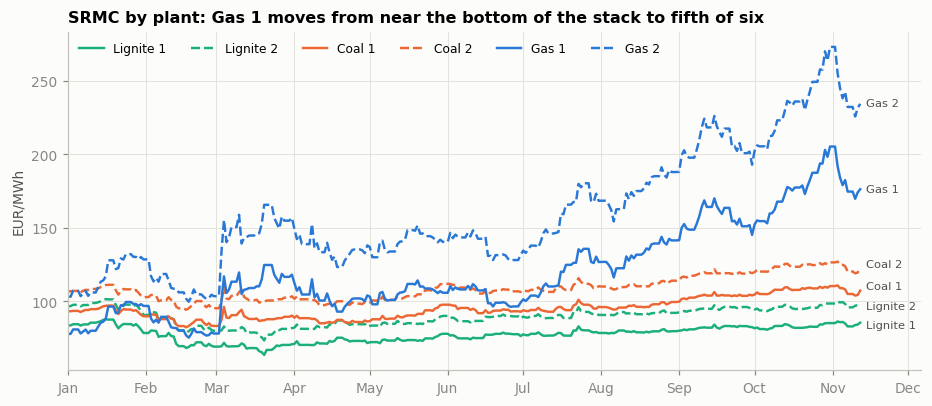

In [11]:
# Line style per plant: colour by fuel, solid for plant 1 (efficient), dashed for plant 2
STYLE = {"lignite_plant_1": (COL["Lignite"], "-"), "lignite_plant_2": (COL["Lignite"], "--"),
         "hard_coal_plant_1": (COL["Hard coal"], "-"), "hard_coal_plant_2": (COL["Hard coal"], "--"),
         "gas_plant_1": (COL["Gas"], "-"), "gas_plant_2": (COL["Gas"], "--")}

def plot_srmc(ax):
    """Each plant's daily SRMC as a line, labelled at the right-hand end."""
    for pl in PLANTS:
        col, ls = STYLE[pl]
        ax.plot(srmc.index, srmc[pl], color=col, ls=ls, label=SHORT[pl])
        # Nudge some labels up or down so the ones that end close together don't overlap
        dy = {"hard_coal_plant_2": 2, "hard_coal_plant_1": 3, "lignite_plant_2": -2, "lignite_plant_1": -2}.get(pl, 0)
        ax.annotate(SHORT[pl], (srmc.index[-1], srmc[pl].iloc[-1]), xytext=(4, dy),
                    textcoords="offset points", va="center", fontsize=7.5, color="#52514e")
    ax.set_ylabel("EUR/MWh")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_xlim(srmc.index[0], srmc.index[-1] + pd.Timedelta(days=24))   # leave room for the labels

fig, ax = plt.subplots(figsize=(10, 4))
plot_srmc(ax)
ax.set_title("SRMC by plant: Gas 1 moves from near the bottom of the stack to fifth of six")
ax.legend(ncol=6, loc="upper left", fontsize=8)
plt.show()

## 4. Dispatch hour by hour

This is the core of the model. For each hour:
1. Residual load = load − wind onshore − wind offshore − solar. That's the demand left over for everything else. It can be negative in windy, sunny hours, which is fine.
2. If residual load is 8,000 MW or less, the must-run block covers it and must-run / renewables set the price.
3. Otherwise I sort the six plants by that day's SRMC, cheapest first, and stack their available capacity on top of the 8 GW block. The first plant whose block reaches the residual load is the marginal plant, and its SRMC is the price for that hour.
4. If residual load is more than 8 GW plus all the available capacity, the hour is "above stack".
5. Each plant generates `clip(residual load − capacity below it, 0, its available capacity)`. So the plants below the marginal one run flat out, the marginal one runs partly, and the ones above it don't run. I need this to work out gas burn.

A made-up example: residual load is 30 GW, and the stack is 8 GW must-run, then Lignite 1 (5 GW), Lignite 2 (5 GW), Coal 1 (4 GW), Coal 2 (4 GW) and Gas 1 (13 GW). The must-run block and the first four plants reach 26 GW, so Gas 1 has to supply the last 4 GW. Gas 1 is the marginal plant and its SRMC is the price.

In [12]:
# Put demand, renewables and plant availability side by side, one row per hour
hourly = lws.merge(avail.drop(columns="day"), on="ts", validate="one_to_one")
# Residual load: demand left after wind and solar (MW)
hourly["residual_mw"] = hourly["load_mw"] - hourly["wind_onshore_mw"] - hourly["wind_offshore_mw"] - hourly["solar_mw"]
assert len(hourly) == len(lws)   # the merge shouldn't add or lose any hours

FUEL = plants["fuel"].to_dict()        # plant -> fuel, e.g. "gas_plant_1" -> "Gas"
EFF = plants["efficiency"].to_dict()   # plant -> efficiency

def dispatch(hourly, srmc, must_run_price=MUST_RUN_PRICE, above_stack_price=ABOVE_STACK_PRICE):
    """Run the merit order for every hour.

    Returns one row per hour with the price, the fuel that set it, the marginal plant,
    each plant's generation (MW) and the gas burned (MWh thermal).

    It works on tables with one row per hour and one column per plant, so the whole
    period runs in one go instead of looping over 7,584 hours. The loop version in the
    next cell does the same thing one hour at a time and is easier to read.
    """
    n = len(hourly)
    S = srmc.loc[hourly["day"], PLANTS].to_numpy()                       # SRMC: each hour gets its day's costs (hours x 6)
    A = hourly[[pl + "_mw" for pl in PLANTS]].to_numpy(dtype=float)      # available capacity in MW (hours x 6)
    rl = hourly["residual_mw"].to_numpy(dtype=float)                     # residual load in MW (one per hour)
    assert not np.isnan(S).any()                                         # every hour needs a cost for every plant

    # Sort the plants by cost, cheapest first. Costs change daily, so the order can change daily too.
    order = np.argsort(S, axis=1, kind="stable")
    S_sorted = np.take_along_axis(S, order, axis=1)                      # costs in merit order
    A_sorted = np.take_along_axis(A, order, axis=1)                      # capacities in merit order
    # Stack the capacities on top of the 8 GW block. For each hour, top[i] is where the
    # i-th cheapest plant's block ends and bottom[i] is where it starts (MW).
    top = MUST_RUN_MW + np.cumsum(A_sorted, axis=1)
    bottom = top - A_sorted

    # Each plant covers whatever residual load is left above the bottom of its block,
    # but never less than zero and never more than its capacity.
    gen_sorted = np.clip(rl[:, None] - bottom, 0, A_sorted)
    # Put generation back into the original plant order (undo the sort)
    gen = np.empty_like(gen_sorted)
    np.put_along_axis(gen, order, gen_sorted, axis=1)

    must_run = rl <= MUST_RUN_MW        # hours the must-run block covers on its own
    above = rl > top[:, -1]             # hours when demand is more than everything available
    # The marginal plant is the first block whose top reaches the residual load. Counting the
    # blocks that end below the residual load gives its position in the merit order.
    # In above-stack hours that count would be 6, one past the end, so I cap it at the last plant.
    k = np.minimum((top < rl[:, None]).sum(axis=1), len(PLANTS) - 1)
    rows = np.arange(n)
    marginal = np.array(PLANTS)[order[rows, k]]                          # name of the marginal plant
    price = S_sorted[rows, k]                                            # its SRMC is the price
    # Above-stack hours: the most expensive plant's SRMC, unless a fixed price is given
    price = np.where(above, S_sorted[:, -1] if above_stack_price is None else above_stack_price, price)
    # Must-run hours: the assumed must-run price
    price = np.where(must_run, must_run_price, price)

    # Which fuel set the price: the marginal plant's fuel, or one of the two special cases
    setter = np.array([FUEL[m] for m in marginal], dtype=object)
    setter[above] = "Above stack"
    setter[must_run] = "Must-run / renewables"
    # No plant is marginal in must-run or above-stack hours
    marginal = np.where(must_run | above, "", marginal)

    # Collect everything into one table, one row per hour
    out = hourly[["ts", "day", "residual_mw"]].copy()
    out["stack_capacity_mw"] = top[:, -1]                                # must-run + all available capacity
    out["price"] = price
    out["setter"] = setter
    out["marginal_plant"] = marginal
    for i, pl in enumerate(PLANTS):
        out["gen_" + pl] = gen[:, i]
    # Gas burned = each gas plant's output divided by its own efficiency (MWh thermal)
    out["gas_burn_mwh_th"] = out["gen_gas_plant_1"] / EFF["gas_plant_1"] + out["gen_gas_plant_2"] / EFF["gas_plant_2"]
    return out

res = dispatch(hourly, srmc)
# How many hours each fuel set the price, and the share of all hours
res["setter"].value_counts().to_frame("hours").assign(share=lambda t: (t["hours"] / len(res)).round(3))

,hours,share
setter,,
Gas,3949,0.521
Must-run / renewables,1277,0.168
Lignite,1109,0.146
Hard coal,1080,0.142
Above stack,169,0.022


In [13]:
# Check 1: the same logic written as a simple loop, one hour at a time. It's slow but easy to
# follow, so if it agrees with dispatch() on a sample of hours, the fast version is right.
def dispatch_one_hour(rl, avail_mw, srmc_day):
    """Dispatch a single hour: walk up the merit order, filling demand plant by plant."""
    if rl <= MUST_RUN_MW:
        return MUST_RUN_PRICE, "Must-run / renewables", {pl: 0.0 for pl in PLANTS}
    gen, covered, price, setter = {pl: 0.0 for pl in PLANTS}, MUST_RUN_MW, None, None
    for pl in sorted(PLANTS, key=lambda x: srmc_day[x]):        # cheapest plant first
        take = min(avail_mw[pl], rl - covered)                  # all of its capacity, or just what's still needed
        gen[pl], covered = take, covered + take
        if covered >= rl:                                       # demand is covered: this plant sets the price
            return srmc_day[pl], FUEL[pl], gen
    return max(srmc_day.values()), "Above stack", gen           # ran out of plants

# 600 random hours, plus 20 above-stack hours added on purpose because they're rare
sample = hourly.sample(600, random_state=1).index.union(res.index[res["setter"] == "Above stack"][:20])
for i in sample:
    h = hourly.loc[i]
    price_i, setter_i, gen_i = dispatch_one_hour(h["residual_mw"], {pl: h[pl + "_mw"] for pl in PLANTS}, srmc.loc[h["day"]].to_dict())
    assert np.isclose(price_i, res.loc[i, "price"]) and setter_i == res.loc[i, "setter"]
    assert all(np.isclose(gen_i[pl], res.loc[i, "gen_" + pl]) for pl in PLANTS)

# Check 2: energy balance. In a normal hour, the 8 GW block plus the six plants' output should
# add up to exactly the residual load. In must-run hours the plants produce nothing, and in
# above-stack hours they all run flat out.
gen_total = res[["gen_" + pl for pl in PLANTS]].sum(axis=1)
normal = ~res["setter"].isin(["Must-run / renewables", "Above stack"])
assert np.allclose(gen_total[normal] + MUST_RUN_MW, res.loc[normal, "residual_mw"])
assert (gen_total[res["setter"] == "Must-run / renewables"] == 0).all()
assert np.allclose(gen_total[res["setter"] == "Above stack"] + MUST_RUN_MW, res.loc[res["setter"] == "Above stack", "stack_capacity_mw"])
# No plant ever produces more than it has available
for pl in PLANTS:
    assert (res["gen_" + pl] <= hourly[pl + "_mw"] + 1e-9).all()
print("Dispatch checks passed.")
print(f"Residual load: min {res['residual_mw'].min():,.0f} MW, max {res['residual_mw'].max():,.0f} MW, "
      f"negative in {(res['residual_mw'] < 0).sum()} hours")
# How short the stack was in the above-stack hours
short = res[res["setter"] == "Above stack"]
print(f"Above stack: {len(short)} hours on {short['day'].nunique()} days, "
      f"average shortfall {(short['residual_mw'] - short['stack_capacity_mw']).mean():,.0f} MW, "
      f"max {(short['residual_mw'] - short['stack_capacity_mw']).max():,.0f} MW")

# Check 3: the edge cases. I take one real hour and set its residual load by hand to the four
# values where the logic switches: exactly 8 GW, just above it, exactly the total capacity,
# and just above that.
base_row = hourly.iloc[[1000]]
srmc_d = srmc.loc[base_row["day"].iloc[0]]
cap_total = MUST_RUN_MW + base_row[[pl + "_mw" for pl in PLANTS]].to_numpy().sum()
cheapest, dearest = srmc_d.idxmin(), srmc_d.idxmax()
cases = {"exactly 8 GW": MUST_RUN_MW, "just above 8 GW": MUST_RUN_MW + 1,
         "exactly total capacity": cap_total, "above total capacity": cap_total + 1}
edge = pd.concat([base_row.assign(residual_mw=v) for v in cases.values()], ignore_index=True)
edge_out = dispatch(edge, srmc)
edge_gen = edge_out[["gen_" + pl for pl in PLANTS]].to_numpy()
edge_full = edge[[pl + "_mw" for pl in PLANTS]].to_numpy()
# Exactly 8 GW: must-run sets the price and no plant runs
assert edge_out.loc[0, "setter"] == "Must-run / renewables" and edge_out.loc[0, "price"] == MUST_RUN_PRICE and (edge_gen[0] == 0).all()
# 1 MW above 8 GW: the cheapest plant is marginal and produces exactly 1 MW
assert edge_out.loc[1, "marginal_plant"] == cheapest and np.isclose(edge_out.loc[1, "price"], srmc_d[cheapest]) and np.isclose(edge_gen[1].sum(), 1)
# Exactly full: the most expensive plant is marginal, everything runs flat out, and it's not above stack
assert edge_out.loc[2, "marginal_plant"] == dearest and edge_out.loc[2, "setter"] != "Above stack" and np.allclose(edge_gen[2], edge_full[2])
# 1 MW over: above stack, priced at the most expensive plant, everything flat out
assert edge_out.loc[3, "setter"] == "Above stack" and np.isclose(edge_out.loc[3, "price"], srmc_d[dearest]) and np.allclose(edge_gen[3], edge_full[3])
# The simple loop gives the same answer in all four cases
for j, rl in enumerate(cases.values()):
    p_j, s_j, _ = dispatch_one_hour(rl, {pl: edge.loc[j, pl + "_mw"] for pl in PLANTS}, srmc_d.to_dict())
    assert np.isclose(p_j, edge_out.loc[j, "price"]) and s_j == edge_out.loc[j, "setter"]
print("Boundary checks passed:", ", ".join(cases))

Dispatch checks passed.
Residual load: min -15,918 MW, max 67,289 MW, negative in 645 hours
Above stack: 169 hours on 53 days, average shortfall 2,674 MW, max 9,733 MW
Boundary checks passed: exactly 8 GW, just above 8 GW, exactly total capacity, above total capacity


## 5. Answers to Q1 to Q4

### Q1. The stack on a January day and a July day

Two ordinary weekdays: 15 January (a Thursday) and 15 July (a Wednesday). Each block's width is the plant's average available capacity that day and its height is the plant's SRMC. The shaded band shows the range of residual load across the day's hours, and the dotted line is its average.

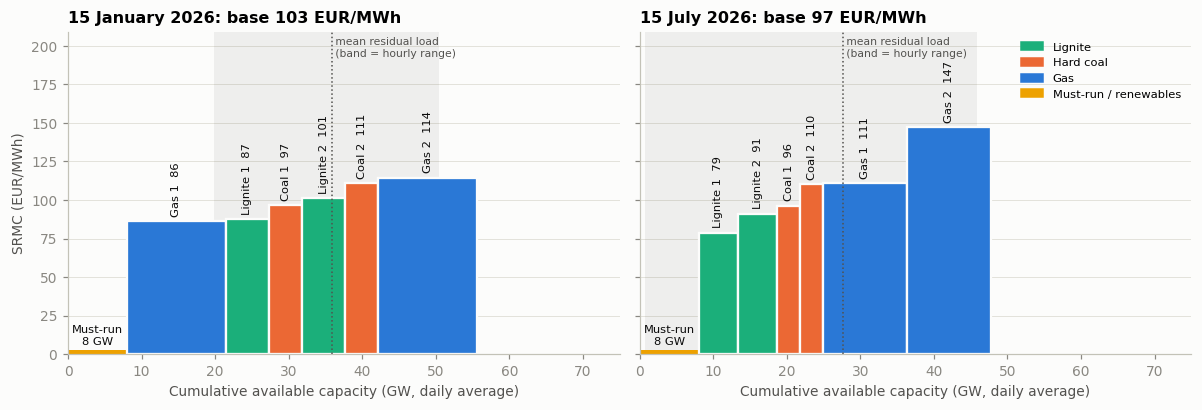

2026-01-15        2026-07-15       
          plant   SRMC      plant   SRMC
rank                                    
1         Gas 1   86.2  Lignite 1   78.6
2     Lignite 1   87.5  Lignite 2   90.9
3        Coal 1   96.7     Coal 1   96.2
4     Lignite 2  101.2     Coal 2  110.2
5        Coal 2  110.7      Gas 1  110.9
6         Gas 2  114.3      Gas 2  147.2

In [14]:
def plot_stack(ax, day, ymax):
    """Draw one day's merit order: plants from left to right, cheapest first."""
    day = pd.Timestamp(day)
    # Each plant's average availability over the day, in GW
    cap = hourly.loc[hourly["day"] == day, [pl + "_mw" for pl in PLANTS]].mean() / 1e3
    cap.index = PLANTS
    order = srmc.loc[day].sort_values(kind="stable").index        # that day's merit order
    # Shade the range of residual load across the day and mark its average
    rl = res.loc[res["day"] == day, "residual_mw"] / 1e3
    ax.axvspan(max(rl.min(), 0), rl.max(), color="#52514e", alpha=0.08, lw=0)
    ax.axvline(rl.mean(), color="#52514e", lw=1, ls=":")
    ax.text(rl.mean(), ymax * 0.985, " mean residual load\n (band = hourly range)", fontsize=7, color="#52514e", va="top")
    # The must-run block: 8 GW at about zero cost, drawn as a thin bar
    ax.bar(0, ymax * 0.012, width=MUST_RUN_MW / 1e3, align="edge", color=COL["Must-run / renewables"])
    ax.text(4, ymax * 0.03, "Must-run\n8 GW", ha="center", fontsize=7.5, color=INK)
    # One bar per plant: width = capacity, height = SRMC
    x = MUST_RUN_MW / 1e3
    for pl in order:
        ax.bar(x, srmc.loc[day, pl], width=cap[pl], align="edge", color=COL[FUEL[pl]],
               edgecolor="#fcfcfb", linewidth=1.5)
        ax.text(x + cap[pl] / 2, srmc.loc[day, pl] + ymax * 0.015, f"{SHORT[pl]}  {srmc.loc[day, pl]:.0f}", rotation=90,
                ha="center", va="bottom", fontsize=7.5, color=INK)
        x += cap[pl]
    ax.set_xlim(0, 75); ax.set_ylim(0, ymax)
    ax.set_xlabel("Cumulative available capacity (GW, daily average)")
    ax.set_title(f"{day:%d %B %Y}: base {res.loc[res['day'] == day, 'price'].mean():.0f} EUR/MWh")
    ax.grid(axis="x", visible=False)

def stack_figure(figsize=(11, 3.8)):
    """The January and July days side by side, on the same price scale."""
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True)
    ymax = srmc.loc[["2026-01-15", "2026-07-15"]].max().max() * 1.42   # headroom for the labels
    plot_stack(axes[0], "2026-01-15", ymax)
    plot_stack(axes[1], "2026-07-15", ymax)
    axes[0].set_ylabel("SRMC (EUR/MWh)")
    axes[1].legend(handles=[Patch(color=COL[f], label=f) for f in ["Lignite", "Hard coal", "Gas", "Must-run / renewables"]],
                   loc="upper right", fontsize=7.5)
    fig.tight_layout()
    return fig

fig = stack_figure()
fig.savefig(OUT / "q1_stack_snapshots.png")
plt.show()

# The same two days as a table: plants ranked from cheapest to most expensive
snap = pd.concat({d: pd.DataFrame({"SRMC": srmc.loc[d].sort_values(kind="stable").round(1)}).rename(index=SHORT)
                  .assign(rank=range(1, 7)).reset_index(names="plant").set_index("rank")
                  for d in ["2026-01-15", "2026-07-15"]}, axis=1)
snap

### Q2. Daily base price and the price-setting fuel

A day's base price is the simple average of its hourly prices (23, 24 or 25 of them). I don't price the day's average residual load instead: the stack is a step function, so that would give a different and wrong answer. A day's price-setting fuel is the fuel that was marginal in the most hours.

In [15]:
def daily_table(res):
    """Turn the hourly results into one row per day: base price, price-setting fuel,
    residual load and gas burn."""
    g = res.groupby("day")
    # How many hours each fuel set the price on each day
    counts = pd.crosstab(res["day"], res["setter"]).reindex(columns=TIE_ORDER, fill_value=0)
    daily = pd.DataFrame({
        "hours": g.size(),                                    # 23, 24 or 25
        "base_price": g["price"].mean(),                      # average of the hourly prices
        "price_setting_fuel": counts.idxmax(axis=1),          # marginal in the most hours; a tie goes to the first in TIE_ORDER
        "tie": counts.eq(counts.max(axis=1), axis=0).sum(axis=1) > 1,
        "residual_load_gw": g["residual_mw"].mean() / 1e3,
        "gas_burn_mcm": g["gas_burn_mwh_th"].sum() / MWH_PER_MCM,   # MWh thermal over the day, in mcm
    })
    for c in TIE_ORDER:
        daily["hours_" + c] = counts[c]
    return daily

daily = daily_table(res)
# Every hour belongs to exactly one day, and days have 23, 24 or 25 hours
assert daily["hours"].sum() == len(res) and set(daily["hours"]) == {23, 24, 25}
# On the clock-change days the average has to use the real number of hours, not 24
for dd in ["2026-03-29", "2026-10-25"]:
    assert np.isclose(daily.loc[dd, "base_price"], res.loc[res["day"] == dd, "price"].sum() / daily.loc[dd, "hours"])

# Save the daily and hourly results so they can be checked outside the notebook
daily.join(px[["gas_eur_mwh", "eua_eur_t", "coal_usd_t", "eurusd"]]).join(srmc.add_prefix("srmc_")) \
     .to_csv(OUT / "daily_results.csv", float_format="%.3f")
res.assign(ts=res["ts"].dt.strftime("%Y-%m-%d %H:%M %z")).to_csv(OUT / "hourly_results.csv", index=False, float_format="%.2f")

print(f"Average base price over the period: {daily['base_price'].mean():.1f} EUR/MWh "
      f"(min {daily['base_price'].min():.1f}, max {daily['base_price'].max():.1f})")
print("Days by price-setting fuel:", daily["price_setting_fuel"].value_counts().to_dict(), "| tie days:", int(daily["tie"].sum()))
daily[["hours", "base_price", "price_setting_fuel", "residual_load_gw", "gas_burn_mcm"]].round(2)

Average base price over the period: 102.2 EUR/MWh (min 0.0, max 259.0)
Days by price-setting fuel: {'Gas': 243, 'Must-run / renewables': 32, 'Lignite': 22, 'Hard coal': 17, 'Above stack': 2} | tie days: 12


,hours,base_price,price_setting_fuel,residual_load_gw,gas_burn_mcm
day,,,,,
2026-01-01,24,3.25,Must-run / renewables,1.32,0.28
2026-01-02,24,55.19,Gas,11.33,20.56
2026-01-03,24,82.13,Gas,19.80,41.32
2026-01-04,24,89.97,Lignite,28.13,48.11
2026-01-05,24,104.00,Gas,45.58,79.44
...,...,...,...,...,...
2026-11-08,24,198.71,Gas,43.75,58.80
2026-11-09,24,232.30,Gas,55.26,103.54
2026-11-10,24,225.79,Gas,55.84,105.83


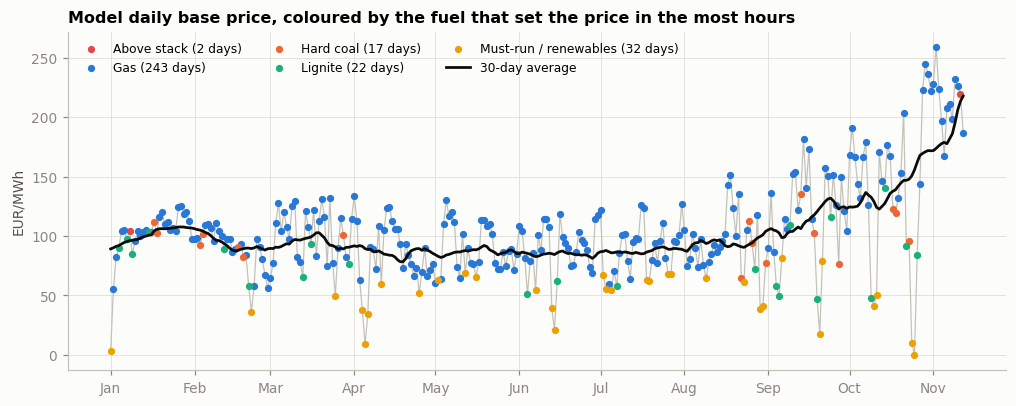

In [16]:
# Daily base price, each day coloured by its price-setting fuel, with a 30-day average on top
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily["base_price"], color="#c3c2b7", lw=0.8, zorder=1)
for f in TIE_ORDER:
    m = daily["price_setting_fuel"] == f
    ax.scatter(daily.index[m], daily.loc[m, "base_price"], s=14, color=COL[f], label=f"{f} ({m.sum()} days)", zorder=2)
ax.plot(daily.index, daily["base_price"].rolling(30, center=True, min_periods=10).mean(), color=INK, lw=1.8, label="30-day average")
ax.set_ylabel("EUR/MWh"); ax.set_title("Model daily base price, coloured by the fuel that set the price in the most hours")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b")); ax.legend(ncol=3, fontsize=8, loc="upper left")
plt.show()

### Q3. How often gas set the price, and what set it otherwise

Shares of hours, by month. November only covers 1 to 12 November, so it's marked with an asterisk and shouldn't be compared directly with full months.

In [17]:
def month_label(idx):
    """Month names for tables and charts. November gets an asterisk because it's a partial month."""
    return [f"{t:%b}" + ("*" if t.month == 11 else "") for t in idx]

res["month"] = res["day"].dt.to_period("M").dt.to_timestamp()
CATS = ["Must-run / renewables", "Lignite", "Hard coal", "Gas", "Above stack"]
# Count the hours each fuel set the price in each month, then turn the counts into shares
share_hours = pd.crosstab(res["month"], res["setter"]).reindex(columns=CATS, fill_value=0)
share = share_hours.div(share_hours.sum(axis=1), axis=0)
overall = share_hours.sum() / share_hours.sum().sum()          # the same over the whole period

# % of hours by fuel and month, plus a row for the whole period and the hours in each month
q3 = (share * 100).round(1)
q3.index = month_label(q3.index)
q3.loc["Period"] = (overall * 100).round(1)
q3["hours"] = list(share_hours.sum(axis=1)) + [len(res)]
q3.to_csv(OUT / "q3_price_setting_share_by_month.csv")
q3

setter,Must-run / renewables,Lignite,Hard coal,Gas,Above stack,hours
Jan,4.0,15.6,19.8,57.1,3.5,744
Feb,5.1,15.6,25.6,52.2,1.5,672
Mar,8.7,19.7,14.0,56.1,1.5,743
Apr,23.5,10.6,12.1,51.4,2.5,720
May,21.4,11.3,9.4,56.3,1.6,744
Jun,22.8,15.7,10.3,48.3,2.9,720
Jul,28.0,12.8,11.6,47.2,0.5,744
Aug,26.1,11.7,16.8,45.4,0.0,744
Sep,19.7,21.7,14.7,42.1,1.8,720
Oct,15.0,17.3,13.3,52.1,2.3,745


Marginal plant, share of all hours (%):
marginal_plant
Gas 1                       30.2
Gas 2                       21.8
(must-run / above stack)    19.1
Lignite 2                    8.3
Coal 2                       8.0
Lignite 1                    6.3
Coal 1                       6.2

Gas sets the price in 52.1% of hours but is running in 62.3% of hours.


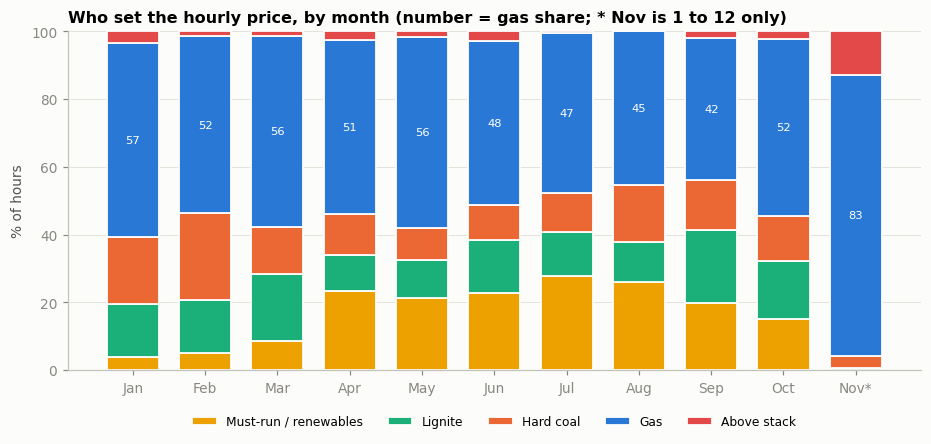

In [18]:
# Which plant was marginal, and how often gas sets the price compared with how often it runs at all
gas_running = (res["gen_gas_plant_1"] + res["gen_gas_plant_2"]) > 0
print("Marginal plant, share of all hours (%):")
print((res["marginal_plant"].replace("", "(must-run / above stack)").map(lambda x: SHORT.get(x, x)).value_counts(normalize=True) * 100).round(1).to_string())
print(f"\nGas sets the price in {100 * overall['Gas']:.1f}% of hours but is running in {100 * gas_running.mean():.1f}% of hours.")

def plot_share(ax):
    """Stacked bars: each month's share of hours set by each fuel, with the gas share written on the bar."""
    bottom = np.zeros(len(share))
    x = np.arange(len(share))
    for c in CATS:
        ax.bar(x, share[c] * 100, bottom=bottom, color=COL[c], width=0.72, edgecolor="#fcfcfb", linewidth=1.2, label=c)
        if c == "Gas":
            for xi, (b, v) in enumerate(zip(bottom, share[c] * 100)):
                if v > 6:                                           # only label bars big enough to hold the number
                    ax.text(xi, b + v / 2, f"{v:.0f}", ha="center", va="center", color="white", fontsize=7.5)
        bottom += (share[c] * 100).to_numpy()
    ax.set_xticks(x); ax.set_xticklabels(month_label(share.index))
    ax.set_ylim(0, 100); ax.set_ylabel("% of hours"); ax.grid(axis="x", visible=False)

fig, ax = plt.subplots(figsize=(10, 4))
plot_share(ax)
ax.set_title("Who set the hourly price, by month (number = gas share; * Nov is 1 to 12 only)")
ax.legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

### Q4. Gas burn

Gas burned (MWh thermal) = each gas plant's output divided by its own efficiency. Dividing by 10,550 gives mcm. This comes from the generation in the dispatch, not from which fuel set the price: gas plants also burn gas when they run underneath the marginal plant, and in above-stack hours both gas plants run flat out.

In [19]:
total_mcm = daily["gas_burn_mcm"].sum()
# It's easy to be out by a factor of 1,000 here, so I recompute the total a different way, via GWh
gwh_th = (res["gen_gas_plant_1"].sum() / 0.60 + res["gen_gas_plant_2"].sum() / 0.45) / 1e3
assert np.isclose(total_mcm, gwh_th / 10.55)
# No day can burn more gas than both gas plants running flat out all day
max_possible = ((hourly["gas_plant_1_mw"] / 0.60 + hourly["gas_plant_2_mw"] / 0.45).groupby(hourly["day"]).sum() / MWH_PER_MCM)
assert (daily["gas_burn_mcm"] <= max_possible + 1e-6).all()

# Monthly summary. Load factor = what Gas 1 produced divided by what it could have produced.
m = daily.groupby(daily.index.to_period("M").to_timestamp())
gen_m = res.groupby("month")[["gen_gas_plant_1", "gen_gas_plant_2"]].sum() / 1e6     # MWh -> TWh
q4 = pd.DataFrame({
    "days": m.size(),
    "gas burn (mcm/d)": m["gas_burn_mcm"].mean(),
    "gas burn (mcm)": m["gas_burn_mcm"].sum(),
    "Gas 1 gen (TWh)": gen_m["gen_gas_plant_1"],
    "Gas 2 gen (TWh)": gen_m["gen_gas_plant_2"],
    "Gas 1 load factor (%)": 100 * res.groupby("month")["gen_gas_plant_1"].sum() / hourly.groupby(res["month"])["gas_plant_1_mw"].sum(),
    "residual load (GW)": m["residual_load_gw"].mean(),
    "base price (EUR/MWh)": m["base_price"].mean(),
})
q4.index = month_label(q4.index)
q4.to_csv(OUT / "q4_gas_burn_by_month.csv", float_format="%.2f")
print(f"Total gas burn 1 Jan to 12 Nov: {total_mcm:,.0f} mcm = {total_mcm / 1e3:.1f} bcm; "
      f"average {daily['gas_burn_mcm'].mean():.1f} mcm/d (min {daily['gas_burn_mcm'].min():.1f}, max {daily['gas_burn_mcm'].max():.1f}; "
      f"physical ceiling if both gas plants ran flat out: about {max_possible.mean():.0f} mcm/d)")
q4.round(1)

Total gas burn 1 Jan to 12 Nov: 9,969 mcm = 10.0 bcm; average 31.5 mcm/d (min 0.0, max 105.8; physical ceiling if both gas plants ran flat out: about 113 mcm/d)


,days,gas burn (mcm/d),gas burn (mcm),Gas 1 gen (TWh),Gas 2 gen (TWh),Gas 1 load factor (%),residual load (GW),base price (EUR/MWh)
Jan,31,60.6,1878.1,9.2,2.0,87.9,37.4,100.9
Feb,28,50.6,1416.2,7.5,1.1,78.0,34.8,88.6
Mar,31,27.1,839.0,4.1,0.9,40.7,29.2,99.7
Apr,30,27.9,836.3,3.9,1.0,42.5,23.6,82.4
May,31,28.4,879.4,4.3,1.0,46.8,22.8,88.3
Jun,30,31.1,933.1,4.1,1.3,47.8,23.0,86.9
Jul,31,20.3,628.5,3.1,0.6,36.6,20.5,86.3
Aug,31,13.7,424.0,2.4,0.2,27.1,19.6,91.4
Sep,30,18.4,553.0,2.6,0.7,30.2,23.1,113.4
Oct,31,26.0,807.3,3.8,1.0,39.0,27.3,138.6


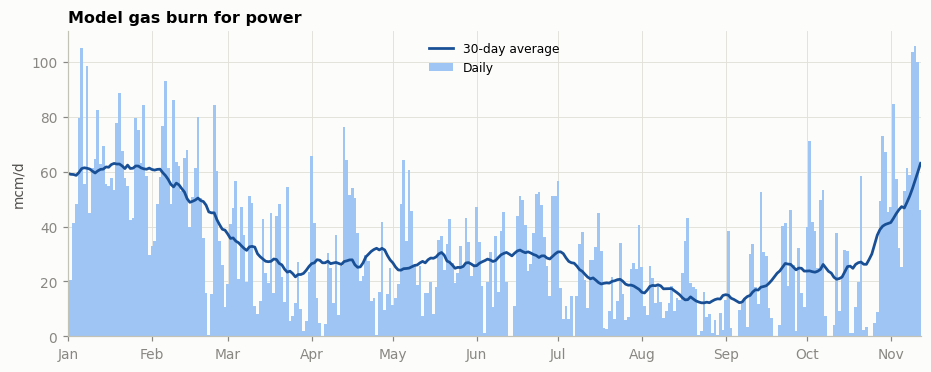

In [20]:
def plot_burn(ax):
    """Daily gas burn as bars, with a 30-day average line."""
    ax.bar(daily.index, daily["gas_burn_mcm"], width=1.0, color="#9ec5f4", label="Daily")
    ax.plot(daily.index, daily["gas_burn_mcm"].rolling(30, center=True, min_periods=10).mean(), color="#184f95", lw=1.8, label="30-day average")
    ax.set_ylabel("mcm/d"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_xlim(daily.index[0], daily.index[-1])

fig, ax = plt.subplots(figsize=(10, 3.6))
plot_burn(ax)
ax.set_title("Model gas burn for power"); ax.legend(fontsize=8, loc="upper center")
plt.show()

### Q3 and Q4 together: setting the price isn't the same as burning gas

Gas set the price in about half of all hours all year, but gas burn fell sharply. The table below shows why. In January the efficient gas plant was one of the cheapest plants, so it often ran flat out underneath the marginal plant. Once gas moved behind coal and lignite, the gas plants only really ran in hours when gas was the marginal fuel. Then the marginal gas plant ran only partly and the other one was often off. So how often gas sets the price doesn't tell you how much gas is burned.

In [21]:
gas_running = (res["gen_gas_plant_1"] + res["gen_gas_plant_2"]) > 0        # at least one gas plant producing
g1_full = np.isclose(res["gen_gas_plant_1"], hourly["gas_plant_1_mw"])     # Gas 1 at full available capacity
g1_marginal = res["marginal_plant"] == "gas_plant_1"                       # Gas 1 setting the price
by_m = lambda s: s.groupby(res["month"]).mean()     # monthly average of a True/False hourly series = share of hours
daily_m = daily.groupby(daily.index.to_period("M").to_timestamp())
marg_vs_burn = pd.DataFrame({
    "gas sets price (% hours)": 100 * by_m(res["setter"] == "Gas"),
    "gas running (% hours)": 100 * by_m(gas_running),
    # Gas 1 flat out but not setting the price means it's running underneath the marginal plant
    "Gas 1 at full output, not marginal (% hours)": 100 * by_m(g1_full & ~g1_marginal),
    "gas burn (mcm/d)": daily_m["gas_burn_mcm"].mean(),
    "base price (EUR/MWh)": daily_m["base_price"].mean(),
})
marg_vs_burn.index = month_label(marg_vs_burn.index)
marg_vs_burn.to_csv(OUT / "marginality_vs_burn_by_month.csv", float_format="%.2f")
marg_vs_burn.round(1)

,gas sets price (% hours),gas running (% hours),"Gas 1 at full output, not marginal (% hours)",gas burn (mcm/d),base price (EUR/MWh)
Jan,57.1,95.7,72.8,60.6,100.9
Feb,52.2,89.6,61.2,50.6,88.6
Mar,56.1,59.2,20.6,27.1,99.7
Apr,51.4,55.8,25.4,27.9,82.4
May,56.3,60.9,27.3,28.4,88.3
Jun,48.3,57.8,37.5,31.1,86.9
Jul,47.2,49.1,21.0,20.3,86.3
Aug,45.4,45.4,9.3,13.7,91.4
Sep,42.1,43.9,16.7,18.4,113.4
Oct,52.1,54.4,22.3,26.0,138.6


## 6. What drove the results

Two charts moving together doesn't prove one caused the other. So instead I rerun the model with some inputs changed and see what happens.

**A. Counterfactuals.** I rerun the dispatch with one input held at its January average while everything else follows what actually happened. The difference from the actual run is that input's contribution, within this simple model. Holding all three prices fixed shows what load, wind, solar and availability did on their own. The model isn't linear, so the pieces don't have to add up exactly to the total. Whatever is left over is reported as an interaction term.

In [22]:
def run(px_alt=None, lignite_fuel=LIGNITE_FUEL_EUR_MWH_TH, must_run_price=MUST_RUN_PRICE, above_stack_price=ABOVE_STACK_PRICE):
    """Rerun the whole model (SRMC, dispatch, daily table) with different prices or assumptions.
    Returns the hourly and the daily results."""
    px_alt = px if px_alt is None else px_alt.copy()
    # Recompute coal in EUR/MWh in case coal or EURUSD were changed
    px_alt["coal_eur_mwh_th"] = px_alt["coal_usd_t"] / px_alt["eurusd"] / COAL_MWH_PER_T
    r = dispatch(hourly, srmc_table(px_alt, lignite_fuel), must_run_price, above_stack_price)
    return r, daily_table(r)

def summary(r, d):
    """Headline numbers for one run: average price, total gas burn, and how often each fuel set the price."""
    return pd.Series({"avg base price": d["base_price"].mean(), "gas burn (bcm)": d["gas_burn_mcm"].sum() / 1e3,
                      "gas sets price (% hours)": 100 * (r["setter"] == "Gas").mean(),
                      "coal sets price (% hours)": 100 * (r["setter"] == "Hard coal").mean(),
                      "lignite sets price (% hours)": 100 * (r["setter"] == "Lignite").mean()})

jan = px.loc["2026-01"].mean()          # January average of each price
def frozen(cols):
    """A copy of the daily prices with the given columns held at their January average all year."""
    alt = px.copy()
    for c in cols:
        alt[c] = jan[c]
    return alt

cf_runs = {"Base (actual prices)": run(),
           "Gas frozen at Jan avg": run(frozen(["gas_eur_mwh"])),
           "Coal + FX frozen at Jan avg": run(frozen(["coal_usd_t", "eurusd"])),
           "EUA frozen at Jan avg": run(frozen(["eua_eur_t"])),
           "All three frozen": run(frozen(["gas_eur_mwh", "coal_usd_t", "eurusd", "eua_eur_t"]))}
base_r, base_d = cf_runs["Base (actual prices)"]
# The base run must reproduce the main results exactly
assert np.allclose(base_d["base_price"], daily["base_price"])

# Monthly averages of each run, for price and for gas burn
to_month = lambda d, col, how: getattr(d[col].groupby(d.index.to_period("M").to_timestamp()), how)()
cf_price = pd.DataFrame({k: to_month(d, "base_price", "mean") for k, (r, d) in cf_runs.items()})
cf_burn = pd.DataFrame({k: to_month(d, "gas_burn_mcm", "mean") for k, (r, d) in cf_runs.items()})
for t in (cf_price, cf_burn):
    t.index = month_label(t.index)
print("Monthly base price, EUR/MWh"); display(cf_price.round(1))
print("Monthly gas burn, mcm/d"); display(cf_burn.round(1))
cf_price.to_csv(OUT / "counterfactual_price_by_month.csv", float_format="%.2f")
cf_burn.to_csv(OUT / "counterfactual_burn_by_month.csv", float_format="%.2f")

Monthly base price, EUR/MWh


,Base (actual prices),Gas frozen at Jan avg,Coal + FX frozen at Jan avg,EUA frozen at Jan avg,All three frozen
Jan,100.9,100.6,100.9,100.7,100.6
Feb,88.6,89.4,88.1,96.3,96.8
Mar,99.7,81.8,98.4,109.1,90.3
Apr,82.4,72.0,82.0,88.3,77.9
May,88.3,75.2,87.7,93.4,80.1
Jun,86.9,76.5,86.2,91.1,79.7
Jul,86.3,70.4,85.6,89.3,72.5
Aug,91.4,70.6,90.1,93.9,72.1
Sep,113.4,79.5,111.6,114.8,78.9
Oct,138.6,86.4,136.4,139.7,85.1


Monthly gas burn, mcm/d


,Base (actual prices),Gas frozen at Jan avg,Coal + FX frozen at Jan avg,EUA frozen at Jan avg,All three frozen
Jan,60.6,58.9,61.1,60.4,58.9
Feb,50.6,48.9,50.2,55.2,52.7
Mar,27.1,35.7,26.9,29.7,42.1
Apr,27.9,36.0,27.7,31.0,37.9
May,28.4,36.1,27.1,30.0,36.7
Jun,31.1,36.7,30.6,32.1,36.7
Jul,20.3,29.3,19.6,21.0,29.3
Aug,13.7,28.2,13.7,13.7,28.2
Sep,18.4,34.0,18.4,18.4,31.0
Oct,26.0,43.7,26.0,26.0,39.8


In [23]:
# Split the change from January to October (the last full month) into its parts
def contribution(table, a="Jan", b="Oct"):
    """For gas, coal and EUA: actual October minus October with that price held at January levels.
    For load, renewables and availability: the January-to-October change with all prices held fixed.
    Whatever those don't explain is the interaction."""
    base = table["Base (actual prices)"]
    out = pd.Series({
        f"{a}": base[a], f"{b}": base[b], "change": base[b] - base[a],
        "from gas": base[b] - table.loc[b, "Gas frozen at Jan avg"],
        "from coal + FX": base[b] - table.loc[b, "Coal + FX frozen at Jan avg"],
        "from EUA": base[b] - table.loc[b, "EUA frozen at Jan avg"],
        "from load, renewables, availability": table.loc[b, "All three frozen"] - table.loc[a, "All three frozen"],
    })
    out["interaction / residual"] = out["change"] - out[["from gas", "from coal + FX", "from EUA", "from load, renewables, availability"]].sum()
    return out

attrib = pd.DataFrame({"base price (EUR/MWh)": contribution(cf_price), "gas burn (mcm/d)": contribution(cf_burn)})
attrib.to_csv(OUT / "attribution_jan_to_oct.csv", float_format="%.2f")
attrib.round(1)

,base price (EUR/MWh),gas burn (mcm/d)
Jan,100.9,60.6
Oct,138.6,26.0
change,37.8,-34.5
from gas,52.2,-17.7
from coal + FX,2.2,0.0
from EUA,-1.0,0.0
"from load, renewables, availability",-15.5,-19.1
interaction / residual,-0.2,2.2


**B. Drivers by month.** Fuel and carbon prices, the cost gap between Gas 1 and the coal and lignite plants (negative means gas is cheaper), demand, wind, solar and available capacity.

In [24]:
mm = lambda s: s.groupby(s.index.to_period("M").to_timestamp()).mean()   # monthly average of a daily series
hm = lambda s: s.groupby(res["month"]).mean()                            # monthly average of an hourly series
drivers = pd.DataFrame({
    "gas (EUR/MWh)": mm(px["gas_eur_mwh"]), "coal (EUR/MWh th)": mm(px["coal_eur_mwh_th"]), "EUA (EUR/t)": mm(px["eua_eur_t"]),
    "Gas 1 - Coal 1 SRMC": mm(srmc["gas_plant_1"] - srmc["hard_coal_plant_1"]),
    "Gas 1 - Coal 2 SRMC": mm(srmc["gas_plant_1"] - srmc["hard_coal_plant_2"]),
    "Gas 1 - Lignite 2 SRMC": mm(srmc["gas_plant_1"] - srmc["lignite_plant_2"]),
    "load (GW)": hm(hourly["load_mw"]) / 1e3,
    "wind (GW)": hm(hourly["wind_onshore_mw"] + hourly["wind_offshore_mw"]) / 1e3,
    "solar (GW)": hm(hourly["solar_mw"]) / 1e3,
    "residual load (GW)": hm(hourly["residual_mw"]) / 1e3,
    "coal + lignite avail (GW)": hm(hourly[[pl + "_mw" for pl in PLANTS[:4]]].sum(axis=1)) / 1e3,
    "gas avail (GW)": hm(hourly[["gas_plant_1_mw", "gas_plant_2_mw"]].sum(axis=1)) / 1e3,
})
drivers.index = month_label(drivers.index)
drivers.to_csv(OUT / "drivers_by_month.csv", float_format="%.2f")
drivers.round(1)

,gas (EUR/MWh),coal (EUR/MWh th),EUA (EUR/t),Gas 1 - Coal 1 SRMC,Gas 1 - Coal 2 SRMC,Gas 1 - Lignite 2 SRMC,load (GW),wind (GW),solar (GW),residual load (GW),coal + lignite avail (GW),gas avail (GW)
Jan,34.2,11.8,88.5,-5.4,-19.0,-9.0,62.2,22.6,2.2,37.4,21.3,28.0
Feb,33.3,12.8,75.3,-3.7,-16.3,-2.1,60.8,22.2,3.8,34.8,21.6,28.7
Mar,51.7,15.7,69.9,22.9,10.0,32.1,54.6,15.5,9.9,29.3,19.9,27.3
Apr,45.1,13.4,74.0,15.1,2.5,18.4,51.1,13.5,14.0,23.6,16.0,25.7
May,47.1,14.6,76.0,14.9,1.7,20.4,47.9,9.5,15.6,22.8,14.5,24.6
Jun,45.1,15.1,79.0,9.4,-4.3,15.2,50.3,11.0,16.3,23.0,14.4,24.1
Jul,53.1,14.8,81.0,22.5,8.7,27.3,50.4,13.6,16.3,20.5,16.2,22.9
Aug,61.5,15.2,82.3,35.3,21.2,40.5,46.7,12.7,14.4,19.6,16.5,23.7
Sep,75.4,17.1,85.6,52.9,37.8,61.4,51.1,16.0,12.0,23.1,18.5,23.8
Oct,86.2,18.8,86.4,66.8,51.1,78.9,53.7,19.5,6.9,27.3,19.0,25.9


**C. Sensitivities.** Each row changes one thing and reruns the model, including my four assumptions. The change columns are measured against the base run.

In [25]:
def shifted(**add):
    """A copy of the daily prices with a fixed amount added, e.g. shifted(gas_eur_mwh=10)."""
    alt = px.copy()
    for c, v in add.items():
        alt[c] = alt[c] + v
    return alt

sens_runs = {
    "Base": run(),
    f"Lignite fuel {0.5 * LIGNITE_FUEL_EUR_MWH_TH:g} (-50%)": run(lignite_fuel=0.5 * LIGNITE_FUEL_EUR_MWH_TH),
    f"Lignite fuel {1.5 * LIGNITE_FUEL_EUR_MWH_TH:g} (+50%)": run(lignite_fuel=1.5 * LIGNITE_FUEL_EUR_MWH_TH),
    "Gas +10 EUR/MWh": run(shifted(gas_eur_mwh=10)),
    "Gas -10 EUR/MWh": run(shifted(gas_eur_mwh=-10)),
    "EUA +10 EUR/t": run(shifted(eua_eur_t=10)),
    "Coal +20 USD/t": run(shifted(coal_usd_t=20)),
    "Must-run hours priced at -20": run(must_run_price=-20.0),
    "Must-run hours priced at +20": run(must_run_price=20.0),
    "Above-stack hours priced at 500": run(above_stack_price=500.0),
}
sens = pd.DataFrame({k: summary(r, d) for k, (r, d) in sens_runs.items()}).T
# Changes against the base run
sens.insert(1, "price change", sens["avg base price"] - sens.loc["Base", "avg base price"])
sens.insert(3, "burn change (bcm)", sens["gas burn (bcm)"] - sens.loc["Base", "gas burn (bcm)"])
sens.to_csv(OUT / "sensitivities.csv", float_format="%.3f")
sens.round(2)

,avg base price,price change,gas burn (bcm),burn change (bcm),gas sets price (% hours),coal sets price (% hours),lignite sets price (% hours)
Base,102.15,0.00,9.97,0.00,52.07,14.24,14.62
Lignite fuel 1.45 (-50%),101.62,-0.54,9.87,-0.10,52.28,14.14,14.52
Lignite fuel 4.35 (+50%),102.72,0.57,10.04,0.07,51.05,14.04,15.84
Gas +10 EUR/MWh,112.80,10.64,9.08,-0.89,55.17,12.32,13.45
Gas -10 EUR/MWh,92.18,-9.97,11.87,1.90,48.72,15.53,16.68
EUA +10 EUR/t,106.83,4.67,10.32,0.35,50.04,14.77,16.13
Coal +20 USD/t,103.03,0.88,10.30,0.33,50.70,15.59,14.65
Must-run hours priced at -20,98.79,-3.37,9.97,0.00,52.07,14.24,14.62
Must-run hours priced at +20,105.52,3.37,9.97,0.00,52.07,14.24,14.62
Above-stack hours priced at 500,109.56,7.40,9.97,0.00,52.07,14.24,14.62


**D. How much does the lignite assumption matter?** Lignite has no market price, so I go well beyond the ±50% test: 0 to 20 EUR/MWh thermal, about five times the top of the published range. The second table shows, for each lignite plant and each rival, the lignite cost at which the two would cost the same. Below that number the lignite plant is cheaper.

In [26]:
# Rerun the model for a wide range of lignite costs (the published range is 1.4 to 4)
sweep = pd.DataFrame({L: summary(*run(lignite_fuel=L)) for L in [0, 1.45, 2.9, 4.35, 6, 8, 10, 15, 20]}).T
sweep.index.name = "lignite fuel (EUR/MWh th)"
sweep.insert(1, "price change vs base", sweep["avg base price"] - sweep.loc[LIGNITE_FUEL_EUR_MWH_TH, "avg base price"])
sweep.insert(3, "burn change vs base (bcm)", sweep["gas burn (bcm)"] - sweep.loc[LIGNITE_FUEL_EUR_MWH_TH, "gas burn (bcm)"])
sweep.to_csv(OUT / "lignite_sweep.csv", float_format="%.3f")
display(sweep.round(2))

# Break-even lignite cost: set the lignite plant's SRMC equal to a rival's SRMC and solve for
# the lignite fuel cost, day by day
def lignite_breakeven(lig, rival):
    r = plants.loc[lig]
    return (srmc[rival] - r["vom_eur_mwh"]) * r["efficiency"] - r["co2_t_per_mwh_th"] * px["eua_eur_t"]

be = pd.DataFrame({f"{SHORT[l]} = {SHORT[c]}": lignite_breakeven(l, c)
                   for l in ["lignite_plant_1", "lignite_plant_2"]
                   for c in ["hard_coal_plant_1", "hard_coal_plant_2", "gas_plant_1"]})
# Lowest, average and highest break-even over the days, and how often lignite is cheaper at my 2.9
be_summary = be.describe().loc[["min", "mean", "max"]].T
be_summary["days lignite is cheaper at base assumption (%)"] = (100 * (be > LIGNITE_FUEL_EUR_MWH_TH).mean()).round(0)
be_summary.round(1)

,avg base price,price change vs base,gas burn (bcm),burn change vs base (bcm),gas sets price (% hours),coal sets price (% hours),lignite sets price (% hours)
lignite fuel (EUR/MWh th),,,,,,,
0.00,101.10,-1.05,9.73,-0.24,53.11,14.23,13.59
1.45,101.62,-0.54,9.87,-0.10,52.28,14.14,14.52
2.90,102.15,0.00,9.97,0.00,52.07,14.24,14.62
4.35,102.72,0.57,10.04,0.07,51.05,14.04,15.84
6.00,103.42,1.26,10.24,0.27,50.55,13.70,16.68
8.00,104.30,2.15,10.44,0.47,50.34,12.92,17.67
10.00,105.25,3.10,10.60,0.63,49.31,12.74,18.88
15.00,107.93,5.78,11.67,1.70,48.17,10.18,22.59
20.00,110.90,8.75,12.86,2.89,47.67,9.74,23.52


,min,mean,max,days lignite is cheaper at base assumption (%)
Lignite 1 = Coal 1,6.8,10.4,14.5,100.0
Lignite 1 = Coal 2,12.6,16.4,21.4,100.0
Lignite 1 = Gas 1,0.3,21.3,54.5,95.0
Lignite 2 = Coal 1,1.2,4.9,8.1,86.0
Lignite 2 = Coal 2,6.4,10.0,14.0,100.0
Lignite 2 = Gas 1,-4.2,14.3,42.4,85.0


In [27]:
# Pass-through: rerun with gas 1 EUR/MWh higher every day and see how far the monthly power
# price and gas burn move
up_r, up_d = run(shifted(gas_eur_mwh=1))
passthrough = pd.DataFrame({
    "power move per +1 gas (EUR/MWh)": to_month(up_d, "base_price", "mean") - to_month(base_d, "base_price", "mean"),
    "gas burn change per +1 gas (mcm/d)": to_month(up_d, "gas_burn_mcm", "mean") - to_month(base_d, "gas_burn_mcm", "mean"),
    "gas sets price (% hours)": 100 * (res["setter"] == "Gas").groupby(res["month"]).mean(),
    # The monthly base price minus Gas 1's cost. It's only a rough guide to Gas 1's margin,
    # because Gas 1 doesn't run in every hour.
    "Gas 1 baseload spark spread proxy (EUR/MWh)": to_month(base_d, "base_price", "mean") - mm(srmc["gas_plant_1"]),
})
passthrough.index = month_label(passthrough.index)
# Carbon: a higher EUA price hurts coal and lignite more than gas, so it can increase gas burn.
# Compare gas burn in the EUA +10 run with the base run, month by month.
eua_r, eua_d = sens_runs["EUA +10 EUR/t"]
eua_burn = to_month(eua_d, "gas_burn_mcm", "mean") - to_month(base_d, "gas_burn_mcm", "mean")
eua_burn.rename(index=lambda t: t.strftime("%b")).to_frame("gas burn change (mcm/d)").to_csv(OUT / "eua_plus10_burn_change_by_month.csv", float_format="%.3f")
print("EUA +10: gas burn by month vs base (mcm/d):")
print((to_month(eua_d, "gas_burn_mcm", "mean") - to_month(base_d, "gas_burn_mcm", "mean")).round(1).rename(index=lambda t: t.strftime("%b")).to_dict())
passthrough.to_csv(OUT / "gas_passthrough_by_month.csv", float_format="%.3f")
passthrough.round(2)

EUA +10: gas burn by month vs base (mcm/d):
{'Jan': 3.7, 'Feb': 1.7, 'Mar': 0.6, 'Apr': 2.5, 'May': 1.4, 'Jun': 1.0, 'Jul': 0.7, 'Aug': 0.0, 'Sep': 0.0, 'Oct': 0.0, 'Nov': 0.0}


,power move per +1 gas (EUR/MWh),gas burn change per +1 gas (mcm/d),gas sets price (% hours),Gas 1 baseload spark spread proxy (EUR/MWh)
Jan,1.22,-0.95,57.12,12.03
Feb,1.03,-0.74,52.23,5.74
Mar,1.06,0.00,56.12,-12.10
Apr,1.03,-0.18,51.39,-19.61
May,1.10,-0.61,56.32,-17.78
Jun,1.03,-0.26,48.33,-16.79
Jul,0.90,0.00,47.18,-31.51
Aug,0.81,0.00,45.43,-40.85
Sep,0.82,0.00,42.08,-43.02
Oct,1.03,0.00,52.08,-36.08


In [28]:
# Fuel-switching levels. Given each day's coal and carbon prices, what gas price would make Gas 1
# cost the same as each coal or lignite plant? When gas is above that level, the other plant is cheaper.
g1 = plants.loc["gas_plant_1"]
switch = pd.DataFrame({
    "gas price (actual)": mm(px["gas_eur_mwh"]),
    **{f"Gas 1 = {SHORT[pl]} at gas of": mm((srmc[pl] - g1["vom_eur_mwh"]) * g1["efficiency"] - g1["co2_t_per_mwh_th"] * px["eua_eur_t"])
       for pl in ["lignite_plant_1", "hard_coal_plant_1", "lignite_plant_2", "hard_coal_plant_2"]},
})
# The other way round: what EUA price would make Gas 1 as cheap as Coal 1 at that month's gas and coal prices?
c1 = plants.loc["hard_coal_plant_1"]
switch["EUA needed for Gas 1 = Coal 1"] = mm(
    (px["gas_eur_mwh"] / g1["efficiency"] + g1["vom_eur_mwh"] - px["coal_eur_mwh_th"] / c1["efficiency"] - c1["vom_eur_mwh"])
    / (c1["co2_t_per_mwh_th"] / c1["efficiency"] - g1["co2_t_per_mwh_th"] / g1["efficiency"]))
switch.index = month_label(switch.index)
switch.to_csv(OUT / "fuel_switching_levels.csv", float_format="%.2f")
switch.round(1)

,gas price (actual),Gas 1 = Lignite 1 at gas of,Gas 1 = Coal 1 at gas of,Gas 1 = Lignite 2 at gas of,Gas 1 = Coal 2 at gas of,EUA needed for Gas 1 = Coal 1
Jan,34.2,31.7,37.5,39.6,45.7,75.2
Feb,33.3,27.7,35.5,34.5,43.1,66.1
Mar,51.7,26.0,38.0,32.4,45.7,126.4
Apr,45.1,27.3,36.0,34.0,43.6,111.4
May,47.1,27.9,38.1,34.8,46.0,112.9
Jun,45.1,28.8,39.4,36.0,47.6,102.2
Jul,53.1,29.4,39.6,36.8,47.9,136.7
Aug,61.5,29.8,40.4,37.3,48.8,169.4
Sep,75.4,30.8,43.6,38.5,52.7,216.3
Oct,86.2,31.1,46.1,38.8,55.5,251.5


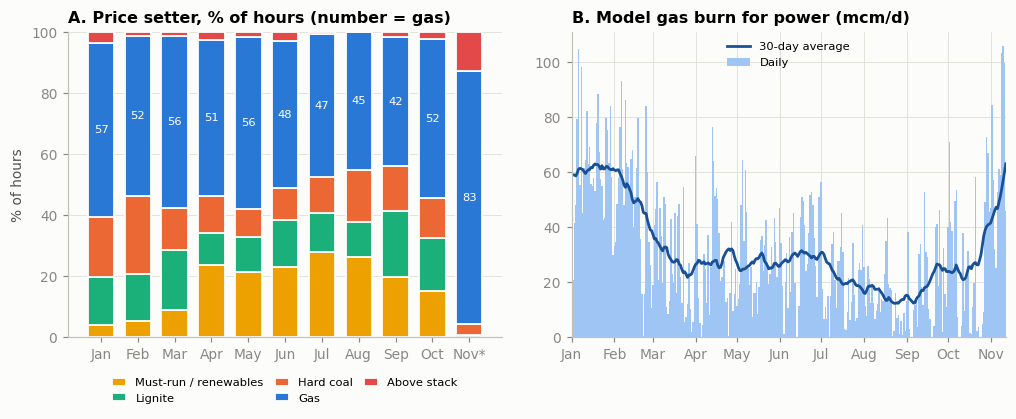

In [29]:
# The two-panel chart used in the one-page note: how often gas set the price (left) and how
# much gas was burned (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"wspace": 0.16})
plot_share(ax1)
ax1.set_title("A. Price setter, % of hours (number = gas)")
ax1.legend(ncol=3, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.1), columnspacing=1, handlelength=1.2)
plot_burn(ax2)
ax2.set_title("B. Model gas burn for power (mcm/d)"); ax2.set_ylabel("")
ax2.legend(fontsize=7.5, loc="upper center")
fig.savefig(OUT / "note_figure.png", bbox_inches="tight")
plt.show()

## Limits of the model (for Q5)

* Six plants and a fixed 8 GW block replace hundreds of real power stations. The supply curve only has six steps, so prices jump between a few levels, and gas burn jumps whenever gas moves past a coal or lignite plant.
* No imports or exports, hydro, pumped storage, batteries or demand response. In reality these smooth out both the must-run hours and the above-stack hours.
* No start-up costs, minimum run times or ramping limits, and no combined heat and power (CHP) plants that have to keep running in winter to supply heat, whatever the power price.
* Must-run hours are priced at 0, but real prices in those hours often go negative. Above-stack hours are priced at the top plant's cost, but real scarcity prices go much higher. I test both in step 6.
* Real day-ahead prices come from bids based on forecasts, not from actual outcomes and plant costs. The lignite fuel cost is my own assumption.
* The brief doesn't include actual power prices, so I haven't checked the model against reality. The price levels are model estimates. What I'd rely on is the direction and timing of the changes.